Simmetrica: True | Diagonale > 0: True
Autovalori: [6.40000000e-05 1.44000000e-04 1.74223788e-04 2.17477621e-03]


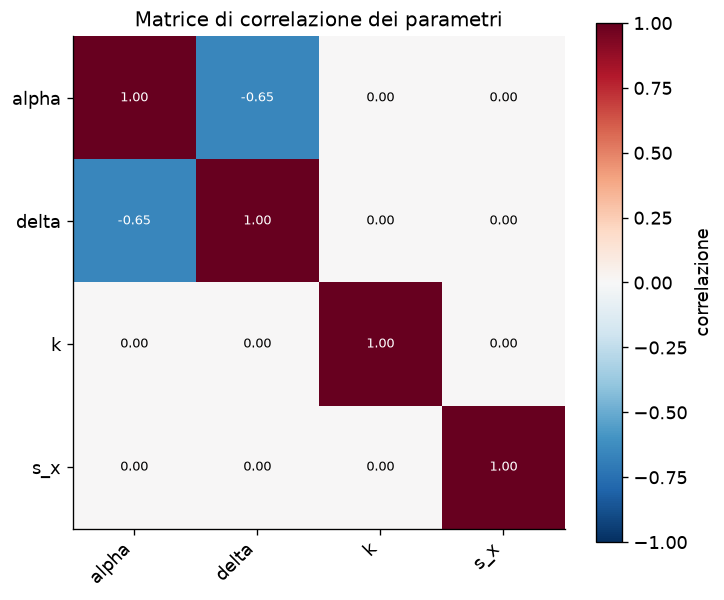

In [79]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import chi2
from scipy.signal import find_peaks

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)

alpha_hat, u_alpha = 0.910, 0.018
delta_hat, u_delta = 5.180, 0.045
rho = -0.65
k = 1.2
u_k = k/100
s_x = 0.8
u_sx = s_x/100

a = alpha_hat/(k*s_x)
d = delta_hat/(k*s_x)

cov_ad = rho*u_alpha*u_delta
C_alphadelta = np.array([
    [u_alpha**2, cov_ad],
    [cov_ad, u_delta**2]
    ])

z = np.array([alpha_hat, delta_hat, k, s_x]).T
C_z = np.array([
    (u_alpha**2, cov_ad, 0, 0),
    (cov_ad, u_delta**2, 0, 0),
    (0, 0, u_k**2, 0),
    (0, 0, 0, u_sx**2)
])

is_sim = np.allclose(C_z, C_z.T)
pos_diag = np.all(np.diag(C_z) > 0)
autovalori = np.linalg.eigvalsh(C_z)
print("Simmetrica:", is_sim, "| Diagonale > 0:", pos_diag)
print("Autovalori:", autovalori)

error = np.sqrt(np.diagonal(C_z))
corr_matrix = C_z / np.outer(error, error)

parametri = ("alpha", "delta", "k", "s_x")
fig, ax = plt.subplots(figsize=(6.2, 5.2))
image = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="RdBu_r") 
ax.set_xticks(range(len(z)), parametri, rotation=45, ha="right")   
ax.set_yticks(range(len(z)), parametri)   
ax.set_title("Matrice di correlazione dei parametri")

for row in range(len(z)): 
    for column in range(len(z)):
        color = "white" if abs(corr_matrix[row, column]) > 0.55 else "black"   
        ax.text(column, row, f"{corr_matrix[row, column]:.2f}",
                ha="center", va="center", fontsize=8, color=color)

fig.colorbar(image, ax=ax, label="correlazione")
plt.tight_layout()      


verifica di q:  True


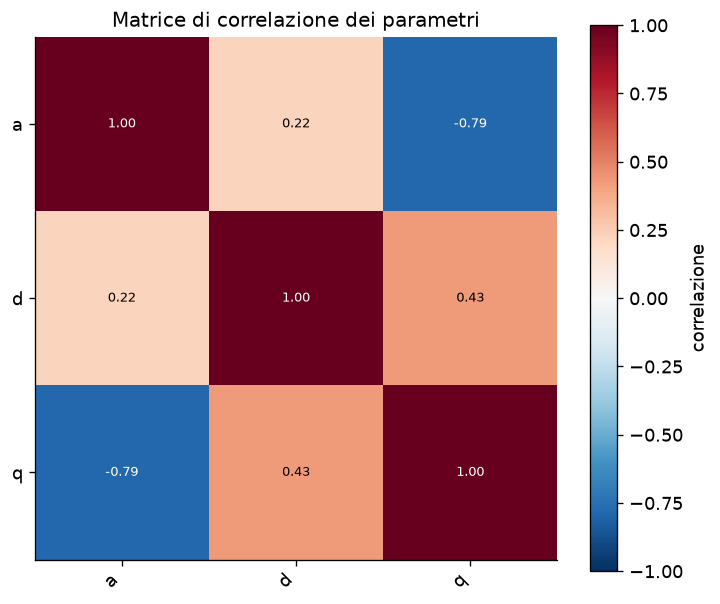

In [80]:
q = d/a
g_z = np.array([a, d, q]).T
J = np.array([
    [1/(k*s_x), 0, -alpha_hat/(s_x*k**2), -alpha_hat/(k*s_x**2)],
    [0, 1/(k*s_x), -delta_hat/(s_x*k**2), -delta_hat/(k*s_x**2)],
    [-delta_hat/alpha_hat**2, 1/alpha_hat, 0, 0]
])
C_g = J @ C_z @ J.T
u_a, u_d, u_q = np.sqrt(np.diag(C_g))

print("verifica di q: ", np.isclose((u_q/q)**2, (u_delta/delta_hat)**2 + (u_alpha/alpha_hat)**2 - 2*cov_ad/(alpha_hat*delta_hat)))

error = np.sqrt(np.diagonal(C_g))
corr_matrix = C_g / np.outer(error, error)

parametri = ("a", "d", "q")
fig, ax = plt.subplots(figsize=(6.2, 5.2))
image = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="RdBu_r") 
ax.set_xticks(range(len(parametri)), parametri, rotation=45, ha="right")   
ax.set_yticks(range(len(parametri)), parametri)   
ax.set_title("Matrice di correlazione dei parametri")

for row in range(len(parametri)): 
    for column in range(len(parametri)):
        color = "white" if abs(corr_matrix[row, column]) > 0.55 else "black"   
        ax.text(column, row, f"{corr_matrix[row, column]:.2f}",
                ha="center", va="center", fontsize=8, color=color)

fig.colorbar(image, ax=ax, label="correlazione")
plt.tight_layout()     


Verifica a > 0:  True | d > 0:  True
Grandezza, Valore nominale, Incertezza lineare, Media MC, Deviazione MC, Intervallo 16 - 84
a  0.9479166666666667 0.02304933190764732 0.9481415745438376 0.023092090741647024 0.9252714051051537  -  0.971101603527656
d  5.395833333333333 0.08955595511869784 5.396855654957392 0.08965580109606425 5.307646585619741  -  5.4862885290662335
q  5.692307692307692 0.14953684832189135 5.694910565637951 0.14995354837789307 5.545670821119018  -  5.843598821960531


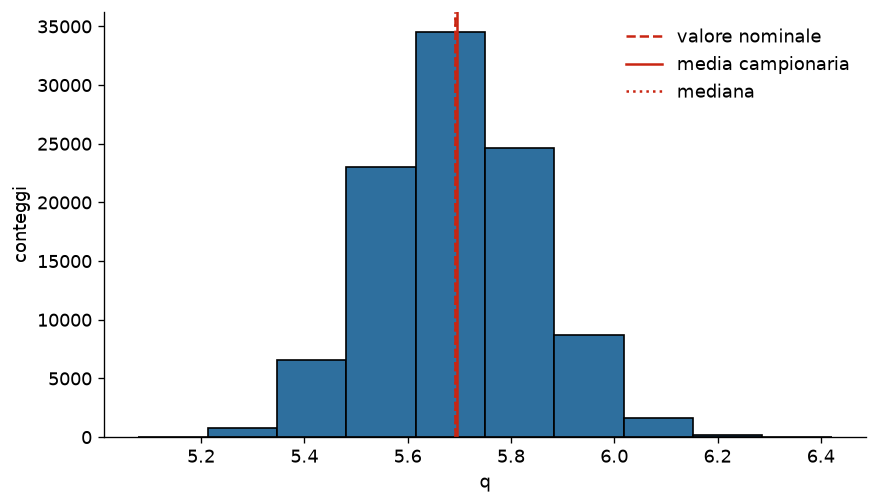

In [81]:
rng = np.random.default_rng(20261003)
M = 100_000
campioni = rng.multivariate_normal(
mean=z,
cov=C_z,
size=M
)
alpha_mc = campioni[:, 0]
delta_mc = campioni[:, 1]
k_mc = campioni[:, 2]
sx_mc = campioni[:, 3]

a_mc = alpha_mc/(k_mc*sx_mc)
d_mc = delta_mc/(k_mc*sx_mc)
q_mc = d_mc/a_mc

print("Verifica a > 0: ", np.all(a_mc)>0, "| d > 0: ", np.all(d_mc)>0)

a_media = np.mean(a_mc)
d_media = np.mean(d_mc)
q_media = np.mean(q_mc)

sigma_a = a_mc.std(ddof=1)
sigma_d = d_mc.std(ddof=1)
sigma_q = q_mc.std(ddof=1)

p16_a, mediana_a, p84_a = np.percentile(a_mc, [16, 50, 84])
p16_d, mediana_d, p84_d = np.percentile(d_mc, [16, 50, 84])
p16_q, mediana_q, p84_q = np.percentile(q_mc, [16, 50, 84])

print("Grandezza, Valore nominale, Incertezza lineare, Media MC, Deviazione MC, Intervallo 16 - 84")
print("a ", a, u_a, a_media, sigma_a, p16_a, " - ", p84_a)
print("d ", d, u_d, d_media, sigma_d, p16_d, " - ", p84_d)
print("q ", q, u_q, q_media, sigma_q, p16_q, " - ", p84_q)

plt.hist(q_mc, color=AZZURRO, edgecolor='black')
plt.axvline(q, color=ROSSO, linestyle='--', label='valore nominale')
plt.axvline(q_media, color=ROSSO, label='media campionaria')
plt.axvline(mediana_q, color=ROSSO, linestyle=':', label='mediana')
plt.xlabel('q')
plt.ylabel('conteggi')
plt.title('')
plt.legend()
plt.show()

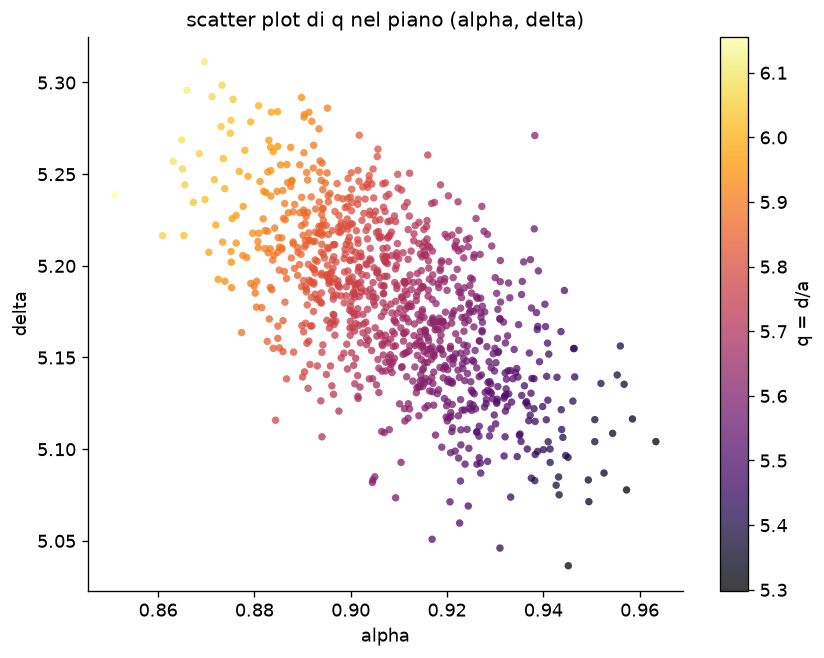

In [82]:
N_plot = 1000
alpha_sub = alpha_mc[:N_plot]
delta_sub = delta_mc[:N_plot]
q_sub = q_mc[:N_plot]

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(
    alpha_sub, 
    delta_sub, 
    c=q_sub, 
    cmap='inferno',
    alpha=0.75, 
    s=20, 
    edgecolors='none'
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('q = d/a')
plt.xlabel('alpha')
plt.ylabel('delta')
plt.title('scatter plot di q nel piano (alpha, delta)')
plt.show()